## Cell 0 — Padding and Pooling

 Create functions for padding, max pooling, and average pooling on a 2D matrix.
Use a 4×4 matrix and show different stride and padding cases with visualization.

In [2]:
import matplotlib.pyplot as plt 
import numpy as np 

## Padding

In [46]:
def apply_padding(input_matrix, pad_size=1, pad_value=0):
    """
    Adds borders around a 2D matrix.
    Formula for output height/width: H_out = H_in + 2 * pad_size
    """
    H, W = input_matrix.shape
    padded = np.full((H + 2 * pad_size, W + 2 * pad_size), pad_value, dtype=input_matrix.dtype)
    padded[pad_size:pad_size + H, pad_size:pad_size + W] = input_matrix
    return padded

In [47]:
# -------------------------------------------------------------
# Demonstration on a 4x4 Feature Map
# -------------------------------------------------------------
sample_input = np.array([
    [10,  2,   0,  15],
    [ 4,  8,   3,   1],
    [ 7,  1,  12,   6],
    [ 9,  5,   2,   4]
])

print("--- Original 4x4 Feature Map ---")
print(sample_input)

# 1. Zero Padding (pad=1)
padded_demo = apply_padding(sample_input, pad_size=1)
print("\n--- Zero Padded (pad=1) [Shape: 6x6] ---")
print(padded_demo)

--- Original 4x4 Feature Map ---
[[10  2  0 15]
 [ 4  8  3  1]
 [ 7  1 12  6]
 [ 9  5  2  4]]

--- Zero Padded (pad=1) [Shape: 6x6] ---
[[ 0  0  0  0  0  0]
 [ 0 10  2  0 15  0]
 [ 0  4  8  3  1  0]
 [ 0  7  1 12  6  0]
 [ 0  9  5  2  4  0]
 [ 0  0  0  0  0  0]]


## Pooling

In [92]:
def pool2d(input_matrix, pool_size=(2, 2), stride=2, padding=0, mode='max'):
    """
    Performs 2D Pooling (Max or Average) with Stride and Padding.

    Output Dimension Formula:
      Output_Size = floor((Input_Size - Pool_Size + 2 * Padding) / Stride) + 1
    """
    # Apply padding if requested
    if padding > 0:
        padded_input = apply_padding(input_matrix, pad_size=padding, pad_value=0)
    else:
        padded_input = input_matrix

    H_in, W_in = padded_input.shape 
    k_h, k_w = pool_size

    # Calculate output dimensions 
    H_out = int(np.floor( ( H_in - k_h ) / stride ) + 1)
    W_out = int(np.floor( ( W_in - k_w ) / stride ) + 1)

    output = np.zeros((H_out,W_out),dtype=float)


    for i in range(H_out): 
        for j in range(W_out):
            # Compute sliding window coordinates

            h_start = i * stride
            h_end = h_start + k_h
            w_start = j * stride
            w_end = w_start + k_w

            # Extract patch
            patch = padded_input[h_start:h_end, w_start:w_end]

            # Apply operation
            if mode == "max": 
                output[i,j] = np.max(patch)
            elif mode == 'avg':
                output[i, j] = np.mean(patch)
            else:
                raise ValueError("Mode must be 'max' or 'avg'")
        
    return output;

In [95]:
sample_input = np.array([
    [10,  2,   0,  15],
    [ 4,  8,   3,   1],
    [ 7,  1,  12,   6],
    [ 9,  5,   2,   4]
])


# 2. Max Pooling (2x2 pool, stride=2, pad=0)
max_pooled = pool2d(sample_input, pool_size=(2, 2), stride=2, padding=0, mode='max')
print("\n--- Max Pooling (2x2, Stride=2) [Shape: 2x2] ---")
print(max_pooled)

# 3. Average Pooling (2x2 pool, stride=2, pad=0)
avg_pooled = pool2d(sample_input, pool_size=(2, 2), stride=2, padding=0, mode='avg')
print("\n--- Average Pooling (2x2, Stride=2) [Shape: 2x2] ---")
print(avg_pooled)

# 4. Pooling with Stride=1 and Padding=1
strided_padded_max = pool2d(sample_input, pool_size=(2, 2), stride=1, padding=1, mode='max')
print("\n--- Max Pooling (2x2, Stride=1, Padding=1) [Shape: 5x5] ---")
print(strided_padded_max)


--- Max Pooling (2x2, Stride=2) [Shape: 2x2] ---
[[10. 15.]
 [ 9. 12.]]

--- Average Pooling (2x2, Stride=2) [Shape: 2x2] ---
[[6.   4.75]
 [5.5  6.  ]]

--- Max Pooling (2x2, Stride=1, Padding=1) [Shape: 5x5] ---
[[10. 10.  2. 15. 15.]
 [10. 10.  8. 15. 15.]
 [ 7.  8. 12. 12.  6.]
 [ 9.  9. 12. 12.  6.]
 [ 9.  9.  5.  4.  4.]]


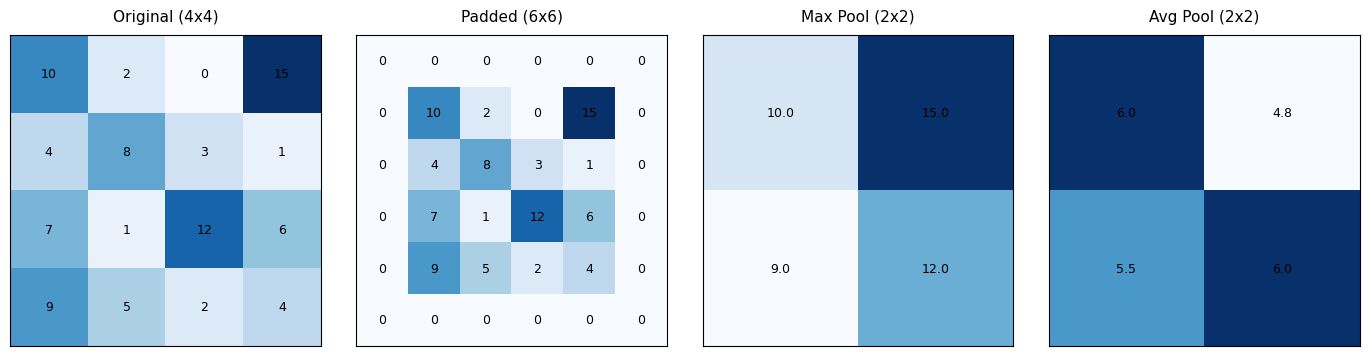

In [98]:
# -------------------------------------------------------------
# Visualization
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))

plots = [
    (sample_input, "Original (4x4)"),
    (padded_demo, "Padded (6x6)"),
    (max_pooled, "Max Pool (2x2)"),
    (avg_pooled, "Avg Pool (2x2)")
]

for ax, (data, title) in zip(axes, plots):
    c = ax.imshow(data, cmap='Blues', interpolation='nearest')
    ax.set_title(title, fontsize=11, pad=10)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data[i, j]:.1f}" if data.dtype == float else f"{data[i, j]}",
                    ha="center", va="center", color="black", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

## Cell 1 — Padding Visualization

### Apply zero padding of size 1 to a 4×4 matrix. Display the original and padded matrices side by side and highlight the padded cells.


In [100]:
import numpy as np
import matplotlib.pyplot as plt

def apply_padding(matrix, pad_size=1, pad_val=0):
    """Pads a 2D matrix manually using index slicing."""
    h, w = matrix.shape
    padded = np.full((h + 2 * pad_size, w + 2 * pad_size), pad_val, dtype=matrix.dtype)
    padded[pad_size:pad_size + h, pad_size:pad_size + w] = matrix
    return padded

In [102]:
# 1. Create a 4x4 sample image/matrix
matrix = np.array([
    [10, 20, 30, 40],
    [50, 60, 70, 80],
    [90, 15, 25, 35],
    [45, 55, 65, 75]
])

pad_size = 1
padded_matrix = apply_padding(matrix, pad_size=pad_size, pad_val=0) 

print(padded_matrix)

[[ 0  0  0  0  0  0]
 [ 0 10 20 30 40  0]
 [ 0 50 60 70 80  0]
 [ 0 90 15 25 35  0]
 [ 0 45 55 65 75  0]
 [ 0  0  0  0  0  0]]


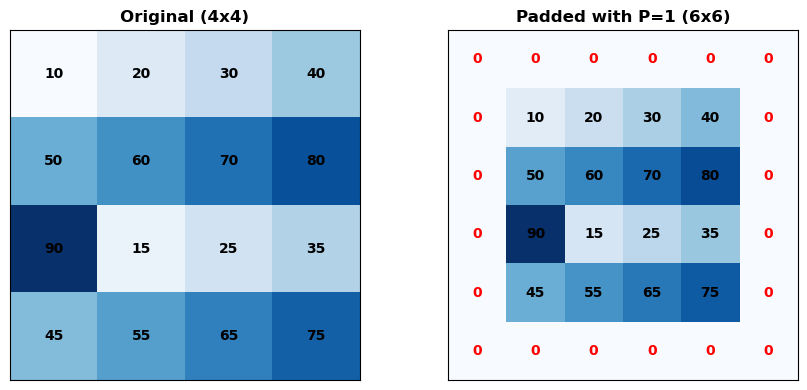

In [103]:
# 2. Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, data, title in zip(axes, [matrix, padded_matrix], ["Original (4x4)", f"Padded with P={pad_size} (6x6)"]):
    im = ax.imshow(data, cmap="Blues", interpolation="nearest")
    ax.set_title(title, fontsize=12, fontweight="bold")
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            val = data[i, j]
            # Color padding cells differently for clarity
            is_padding = (title.startswith("Padded") and
                          (i < pad_size or i >= data.shape[0] - pad_size or
                           j < pad_size or j >= data.shape[1] - pad_size))
            color = "red" if is_padding else "black"
            ax.text(j, i, f"{val}", ha="center", va="center", color=color, fontweight="bold")
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

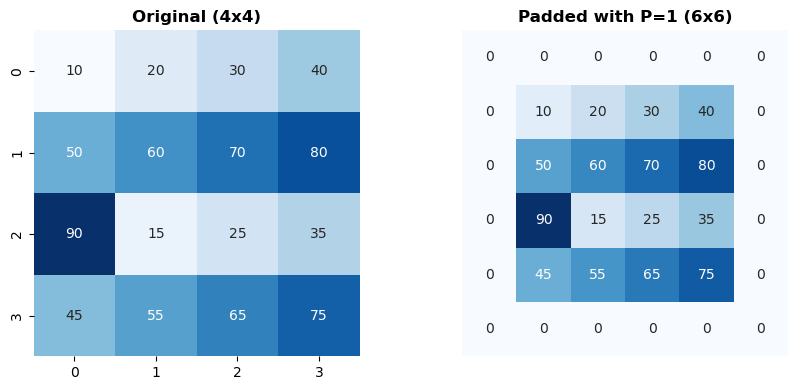

In [126]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

# Plot Original Matrix
sns.heatmap(matrix, ax=axes[0], annot=True, cbar=False, cmap="Blues", square=True)
axes[0].set_title("Original (4x4)", fontweight="bold")

# Plot Padded Matrix
sns.heatmap(padded_matrix, ax=axes[1], annot=True, cbar=False, cmap="Blues", square=True)
axes[1].set_title(f"Padded with P={pad_size} (6x6)", fontweight="bold")

plt.axis("off")
plt.tight_layout()
plt.show()

# Cell 2 — Stride

Use a 2×2 sliding window on a 6×6 matrix. Compare the output for stride 1 and stride 2, and display the output shapes and values.

In [129]:
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np

In [158]:
def extract_strided_patches(matrix,kernal_size=(2,2),stride=1): 
    """
     Extracts patches and sums each window to demonstrate stride steps.
    """
    h_in , w_in = matrix.shape 
    k_h, k_w = kernal_size
    h_out = int(np.floor(( h_in - k_h ) / stride ) + 1)
    w_out = int(np.floor(( w_in - k_w ) / stride ) + 1)

    output = np.zeros((h_out,w_out),dtype=float)

    for i in range(h_out): 
        for j in range(w_out): 
            h_start , w_start = i * stride , j * stride
            patch = matrix[h_start : h_start + k_h , w_start: w_start + k_w]

            output[i , j ] = np.sum(patch)
    return output

In [159]:
# 1. Define a 6x6 feature map
matrix = np.arange(1,37).reshape(6,6)

# 2. Compare Stride 1 vs Stride 2 (2x2 window)
out_s1 = extract_strided_patches(matrix,kernal_size=(2,2),stride=1)
out_s2 = extract_strided_patches(matrix,kernal_size=(2,2),stride=2)

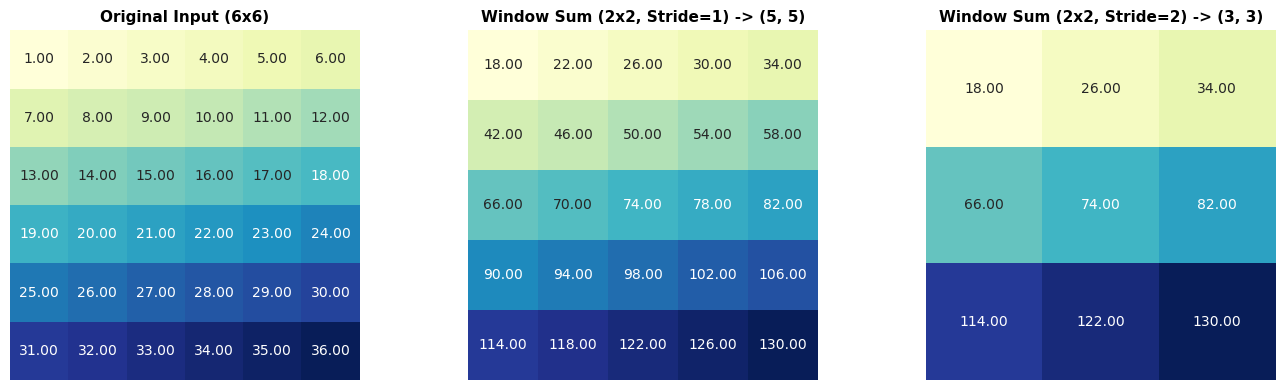

In [160]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
datasets = [
    (matrix, f"Original Input ({matrix.shape[0]}x{matrix.shape[1]})"),
    (out_s1, f"Window Sum (2x2, Stride=1) -> {out_s1.shape}"),
    (out_s2, f"Window Sum (2x2, Stride=2) -> {out_s2.shape}"),
]

for ax, (data, title) in zip(axes, datasets):
    sns.heatmap(data,ax=ax,annot=True,fmt=".2f",cbar=False,cmap="YlGnBu",square=True)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()

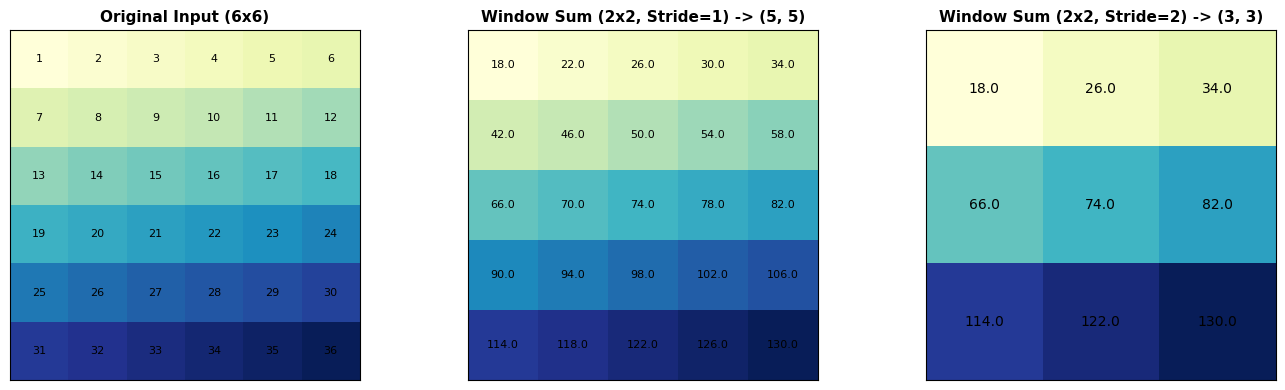

In [161]:
# 3. Visualize

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
datasets = [
    (matrix, "Original Input (6x6)"),
    (out_s1, f"Window Sum (2x2, Stride=1) -> {out_s1.shape}"),
    (out_s2, f"Window Sum (2x2, Stride=2) -> {out_s2.shape}")
]

for ax, (data, title) in zip(axes, datasets):
    ax.imshow(data, cmap="YlGnBu", interpolation="nearest")
    ax.set_title(title, fontsize=11, fontweight="bold")
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data[i, j]}", ha="center", va="center", fontsize=8 if data.shape[0] > 4 else 10)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

## Cell 3 — Max Pooling

Implement max pooling from scratch on a 4×4 matrix using a 2×2 window and stride 2. Highlight the maximum value from each pooling region.

In [163]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [165]:
def max_pool2d(matrix, pool_size=(2, 2), stride=2):
    """Computes 2D Max Pooling from scratch."""
    h_in, w_in = matrix.shape
    kh, kw = pool_size
    h_out = int(np.floor((h_in - kh) / stride) + 1)
    w_out = int(np.floor((w_in - kw) / stride) + 1)

    output = np.zeros((h_out, w_out), dtype=matrix.dtype)
    for i in range(h_out):
        for j in range(w_out):
            h_start, w_start = i * stride, j * stride
            patch = matrix[h_start:h_start + kh, w_start:w_start + kw]
            output[i, j] = np.max(patch)
    return output

In [168]:
# 1. 4x4 input grid
matrix = np.array([
    [12, 20, 30, 45],
    [ 8, 15,  5, 90],
    [34, 70, 11, 23],
    [ 2, 85, 40, 60]
])

pooled = max_pool2d(matrix, pool_size=(2, 2), stride=2)

print(pooled)

[[20 90]
 [85 60]]


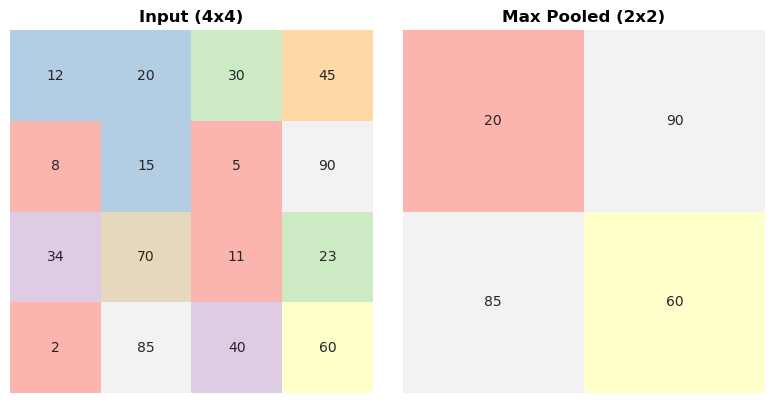

In [182]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# 1. Input Matrix
sns.heatmap(matrix, ax=axes[0],annot=True,fmt="d",cbar=False,    cmap="Pastel1",    square=True,)
axes[0].set_title("Input (4x4)", fontweight="bold")
axes[0].axis("off")

# 2. Max Pooled Output
sns.heatmap(pooled,ax=axes[1],annot=True,fmt="d",cbar=False,cmap="Pastel1",square=True)
axes[1].set_title("Max Pooled (2x2)", fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Cell 4 — Average Pooling

Implement average pooling from scratch on a 4×4 matrix using a 2×2 window and stride 2. Display the input and pooled output.

In [176]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [185]:
def avg_pool2d(matrix, pool_size=(2, 2), stride=2):
    """Computes 2D Average Pooling from scratch."""
    h_in, w_in = matrix.shape
    kh, kw = pool_size
    h_out = int(np.floor((h_in - kh) / stride) + 1)
    w_out = int(np.floor((w_in - kw) / stride) + 1)

    output = np.zeros((h_out, w_out), dtype=matrix.dtype)
    for i in range(h_out):
        for j in range(w_out):
            h_start, w_start = i * stride, j * stride
            patch = matrix[h_start:h_start + kh, w_start:w_start + kw]
            output[i, j] = np.mean(patch)
    return output

In [186]:
# 1. 4x4 input grid
matrix = np.array([
    [10, 20, 30, 40],
    [10, 20, 30, 40],
    [50, 60, 70, 80],
    [50, 60, 70, 80]
], dtype=float)

pooled = avg_pool2d(matrix, pool_size=(2, 2), stride=2)

print(pooled)

[[15. 35.]
 [55. 75.]]


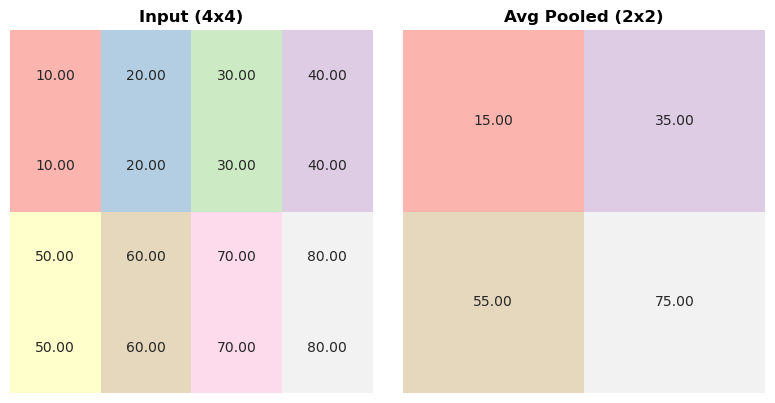

In [190]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# 1. Input Matrix
sns.heatmap(matrix, ax=axes[0],annot=True,fmt=".2f",cbar=False,cmap="Pastel1",square=True,)
axes[0].set_title("Input (4x4)", fontweight="bold")
axes[0].axis("off")

# 2. Avg Pooled Output
sns.heatmap(pooled,ax=axes[1],annot=True,fmt=".2f",cbar=False,cmap="Pastel1",square=True)
axes[1].set_title("Avg Pooled (2x2)", fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Cell 5 — XOR Backpropagation

Create a 2–2–1 neural network using NumPy and train it on the XOR problem using forward propagation and backpropagation. Print the loss and final predictions.

In [5]:
import numpy as np

# 1. Activations
sigmoid = lambda x: 1 / (1 + np.exp(-x))
sigmoid_prime = lambda a: a * (1 - a)

# 2. XOR Data
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])

# 3. Parameter Initialization
np.random.seed(42)
W1 = np.random.uniform(-1, 1, (2, 2))
b1 = np.zeros((1, 2))
W2 = np.random.uniform(-1, 1, (2, 1))
b2 = np.zeros((1, 1))

lr = 1.0

# 4. Training
for epoch in range(10000):
    # Forward Pass
    a1 = sigmoid(np.dot(X, W1) + b1)
    a2 = sigmoid(np.dot(a1, W2) + b2)

    # Loss
    loss = np.mean((a2 - y) ** 2)

    # Backward Pass
    delta2 = (a2 - y) * sigmoid_prime(a2)
    delta1 = np.dot(delta2, W2.T) * sigmoid_prime(a1)

    # Gradient Descent Updates
    W2 -= lr * np.dot(a1.T, delta2)
    b2 -= lr * np.sum(delta2, axis=0, keepdims=True)
    W1 -= lr * np.dot(X.T, delta1)
    b1 -= lr * np.sum(delta1, axis=0, keepdims=True)

    if (epoch + 1) % 2000 == 0:
        print(f"Epoch {epoch + 1:5d} | Loss: {loss:.4f}")

# 5. Output Results
print("\nPredictions:")
for inp, pred, target in zip(X, a2, y):
    print(f"Input: {inp} -> Predicted: {pred[0]:.4f} (Target: {target[0]})")

Epoch  2000 | Loss: 0.0021
Epoch  4000 | Loss: 0.0008
Epoch  6000 | Loss: 0.0005
Epoch  8000 | Loss: 0.0003
Epoch 10000 | Loss: 0.0003

Predictions:
Input: [0 0] -> Predicted: 0.0153 (Target: 0)
Input: [0 1] -> Predicted: 0.9828 (Target: 1)
Input: [1 0] -> Predicted: 0.9828 (Target: 1)
Input: [1 1] -> Predicted: 0.0139 (Target: 0)


In [14]:
import numpy as np 

In [15]:
# 1. Activations Functions
sigmoid = lambda x: 1 / ( 1 + np.exp(-x))
sigmoid_prime = lambda a : a  * ( 1 - a)

# 2. XOR Data
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]) # 4x2 matrix
y = np.array([[0], [1], [1], [0]]) # 4x1 matrix

# 3. Parameter Initialization
np.random.seed(42)
W1 = np.random.uniform(-1,1,(2,2)) # 2x2 matrix 
b1 = np.zeros((1,2))  # 1x2 matrix
W2 = np.random.uniform(-1,1,(2,1)) # 2x1 matrix 
b2 = np.zeros((1,1))  # 1x1 matrix

# Learning rate
lr = 1.0

In [16]:
# 4. Training

for epoch in range(10000): 
    # Forward Pass [ input -> hidden -> output ]
    a1 = sigmoid(np.dot(X , W1) + b1)
    a2 = sigmoid(np.dot(a1 , W2) + b2)

    # Loss 
    loss = np.mean((a2 - y ) ** 2)
    # print("Loss:",loss)

    # Backward Pass [ input <- hidden <- output ]
    delta2 = ( a2 - y ) * sigmoid_prime(a2)
    delta1 = np.dot(delta2,W2.T) * sigmoid_prime(a1)

    # Gradient Descent Updates 
    W2 -= lr * np.dot(a1.T, delta2)
    b2 -= lr * np.sum(delta2, axis=0, keepdims=True)
    W1 -= lr * np.dot(X.T, delta1)
    b1 -= lr * np.sum(delta1 , axis=0, keepdims=True)

    

    if (epoch + 1) % 2000 == 0:
        print(f"Epoch {epoch + 1:5d} | Loss: {loss:.4f}")

Epoch  2000 | Loss: 0.0021
Epoch  4000 | Loss: 0.0008
Epoch  6000 | Loss: 0.0005
Epoch  8000 | Loss: 0.0003
Epoch 10000 | Loss: 0.0003


In [17]:
# 5. Output Results
print("\nPredictions:")
for inp, pred, target in zip(X, a2, y):
    print(f"Input: {inp} -> Predicted: {pred[0]:.4f} (Target: {target[0]})")


Predictions:
Input: [0 0] -> Predicted: 0.0153 (Target: 0)
Input: [0 1] -> Predicted: 0.9828 (Target: 1)
Input: [1 0] -> Predicted: 0.9828 (Target: 1)
Input: [1 1] -> Predicted: 0.0139 (Target: 0)


## Cell 6 — Activation Functions

Implement sigmoid, tanh, ReLU, leaky ReLU, and softmax with their derivatives. Print their outputs and plot each activation with its derivative.

In [191]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [194]:
# =====================================================================
# 1. FUNCTION DEFINITIONS & DERIVATIVES (FROM SCRATCH)
# =====================================================================

def sigmoid(z): 
    return 1.0 / ( 1 + np.exp(-z))

def sigmoid_prime(z): 
    s = sigmoid(z)
    return s * ( 1.0 - s)

def tanh(z): 
    return (np.exp(z) - np.exp(-z)) / (np.exp(z) + np.exp(-z))

def tanh_prime(z):
    t = tanh(z) 
    return 1.0 - t ** 2

def relu(z): 
    return np.maximum(0 , z)

def relu_prime(z): 
    return np.where( z > 0 , 1.0 , 0)

def leaky_relu(z, alpha=0.1):
    return np.where(z > 0, z, alpha * z)

def leaky_relu_prime(z, alpha=0.1):
    return np.where(z > 0, 1.0, alpha)

def softmax(z): 
    # Shift z by subtracting max(z) for numerical stability (prevents overflow)
    exp_z = np.exp( z - np.max(z))
    return exp_z / np.sum(exp_z)

In [198]:
# =====================================================================
# 2. CLASSROOM DEMO: PASSING THE SAME INPUT THROUGH EACH FUNCTION
# =====================================================================

# Raw pre-activation scores (logits) from a neuron:
sample_inputs = np.array([-3.0, -1.0, 0.0, 2.0, 5.0])

print("=" * 65)
print(f"INPUT TENSOR (Pre-activations z): {sample_inputs}")
print("=" * 65)

print("\n1. SIGMOID (Squashes everything between 0 and 1):")
print("   Output:    ", np.round(sigmoid(sample_inputs), 4))
print("   Derivative:", np.round(sigmoid_prime(sample_inputs), 4))
print("   -> Notice how gradients for -3.0 and 5.0 are nearly 0 (Vanishing Gradient).")

print("\n2. TANH (Zero-centered, squashes between -1 and 1):")
print("   Output:    ", np.round(tanh(sample_inputs), 4))
print("   Derivative:", np.round(tanh_prime(sample_inputs), 4))
print("   -> Negative inputs stay negative, but gradients still saturate at extremes.")

print("\n3. ReLU (Rectified Linear Unit: 0 for negative, linear for positive):")
print("   Output:    ", np.round(relu(sample_inputs), 4))
print("   Derivative:", np.round(relu_prime(sample_inputs), 4))
print("   -> Gradient is exactly 1.0 for positive values (fast training, no vanishing gradient).")
print("   -> But for negative values, gradient is 0.0 (Dying ReLU problem).")

print("\n4. LEAKY ReLU (Allows a small slope for negative values):")
print("   Output:    ", np.round(leaky_relu(sample_inputs, alpha=0.1), 4))
print("   Derivative:", np.round(leaky_relu_prime(sample_inputs, alpha=0.1), 4))
print("   -> Gradient never hits 0, so negative neurons can still recover during training.")

print("\n5. SOFTMAX (Multi-Class Probability Distribution):")
multi_class_logits = np.array([2.0, 1.0, 0.1])
probs = softmax(multi_class_logits)
print(f"   Raw Class Logits (e.g. Cat, Dog, Bird): {multi_class_logits}")
print(f"   Softmax Probabilities:                  {np.round(probs, 4)}")
print(f"   Sum of Probabilities:                   {np.sum(probs):.1f} (Always sums to 1.0)")
print("=" * 65)

INPUT TENSOR (Pre-activations z): [-3. -1.  0.  2.  5.]

1. SIGMOID (Squashes everything between 0 and 1):
   Output:     [0.0474 0.2689 0.5    0.8808 0.9933]
   Derivative: [0.0452 0.1966 0.25   0.105  0.0066]
   -> Notice how gradients for -3.0 and 5.0 are nearly 0 (Vanishing Gradient).

2. TANH (Zero-centered, squashes between -1 and 1):
   Output:     [-0.9951 -0.7616  0.      0.964   0.9999]
   Derivative: [9.90e-03 4.20e-01 1.00e+00 7.07e-02 2.00e-04]
   -> Negative inputs stay negative, but gradients still saturate at extremes.

3. ReLU (Rectified Linear Unit: 0 for negative, linear for positive):
   Output:     [0. 0. 0. 2. 5.]
   Derivative: [0. 0. 0. 1. 1.]
   -> Gradient is exactly 1.0 for positive values (fast training, no vanishing gradient).
   -> But for negative values, gradient is 0.0 (Dying ReLU problem).

4. LEAKY ReLU (Allows a small slope for negative values):
   Output:     [-0.3 -0.1  0.   2.   5. ]
   Derivative: [0.1 0.1 0.1 1.  1. ]
   -> Gradient never hits 0

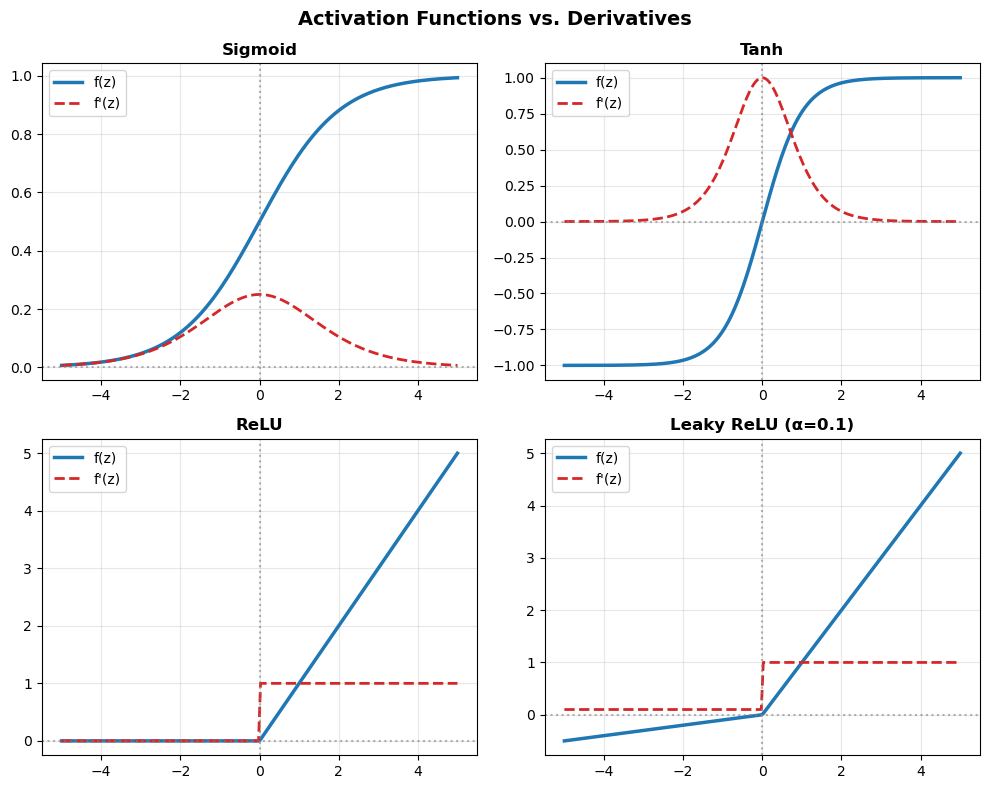

In [199]:
import matplotlib.pyplot as plt
import numpy as np

# Define activation functions and their derivatives
funcs = {
    "Sigmoid": (sigmoid, sigmoid_prime),
    "Tanh": (tanh, tanh_prime),
    "ReLU": (relu, relu_prime),
    "Leaky ReLU (α=0.1)": (
        lambda z: leaky_relu(z, 0.1),
        lambda z: leaky_relu_prime(z, 0.1),
    ),
}

z = np.linspace(-5, 5, 200)
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, (name, (f, f_prime)) in zip(axes.flatten(), funcs.items()):
    ax.plot(z, f(z), label="f(z)", color="tab:blue", lw=2.5)
    ax.plot(z, f_prime(z), label="f'(z)", color="tab:red", ls="--", lw=2)

    ax.axhline(0, color="gray", ls=":", alpha=0.6)
    ax.axvline(0, color="gray", ls=":", alpha=0.6)
    ax.set_title(name, fontweight="bold")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle(
    "Activation Functions vs. Derivatives", fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()

## Cell 7 — Vanishing Gradient

Simulate gradient backpropagation through a 5-layer network using sigmoid and ReLU. Compare and plot the gradient norms at each layer.

# Cell 8 — Exploding Gradient

Simulate a 6-layer network using normal and large weight initialization. Compare and plot the gradient norms to demonstrate exploding gradients.